In [33]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.preprocessing import StandardScaler
from sklearn.manifold import TSNE
from umap import UMAP

In [34]:
df_2022 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2022.parquet")
df_2023 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2023.parquet")
df_2024 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2024.parquet")
df_2025 = pd.read_parquet("year_TERZ_parquets/TERZ_HHZ_hw6_ont25_2025.parquet")

df = pd.concat([df_2022, df_2023, df_2024, df_2025], ignore_index=True)
print(f"Combined dataset shape: {df.shape}")

Combined dataset shape: (64382, 1238)


In [35]:
df.head(5)

,year,station,channel,file,date,month_year,trigger_time,q_value,feature_0000,feature_0001,...,feature_1220,feature_1221,feature_1222,feature_1223,feature_1224,feature_1225,feature_1226,feature_1227,feature_1228,feature_1229
0,2022,TERZ,HHZ,TERZ_HHZ_2022-06-09.mseed,2022-06-09,jun_2022,2022-06-09T15:27:49.040000Z,23.925580,0.110069,0.076217,...,50.000000,28.850130,29.419859,12.191085,22.311697,4.561096,2.034374,3.903897,2.649643,5.189702
1,2022,TERZ,HHZ,TERZ_HHZ_2022-06-09.mseed,2022-06-09,jun_2022,2022-06-09T15:28:01.085000Z,13.374806,0.715210,1.442595,...,30.555073,20.579399,7.321030,4.691075,12.052446,4.002035,5.551497,12.511168,16.844212,20.855711
2,2022,TERZ,HHZ,TERZ_HHZ_2022-06-09.mseed,2022-06-09,jun_2022,2022-06-09T15:44:44.820000Z,23.925580,0.299059,0.251231,...,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,35.450333,33.866257,50.000000
3,2022,TERZ,HHZ,TERZ_HHZ_2022-06-09.mseed,2022-06-09,jun_2022,2022-06-09T15:50:36.200000Z,13.374806,0.575410,0.528327,...,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000,50.000000
4,2022,TERZ,HHZ,TERZ_HHZ_2022-06-09.mseed,2022-06-09,jun_2022,2022-06-09T15:56:10.655000Z,13.374806,1.479329,1.268577,...,43.452965,39.932377,13.558736,33.853756,50.000000,33.669014,50.000000,50.000000,50.000000,50.000000


In [36]:
feature_columns = [col for col in df.columns if col.startswith("feature_")]
if len(feature_columns) == 0:
    raise ValueError("No feature_* columns found.")

X = df[feature_columns].to_numpy(dtype=np.float64)

print(f"Feature matrix: X.shape = {X.shape}")

Feature matrix: X.shape = (64382, 1230)


In [37]:
X_max = X.max(axis=1, keepdims=True)
X_norm = X / X_max
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_norm)
print(f"Scaled matrix: {X_scaled.shape}") 

Scaled matrix: (64382, 1230)


\sqrt(64382) \approx 253.74 (we will use this value as the first attempt for perplexity)

In [38]:
RANDOM_STATE = 42
METRIC = "euclidean"
PERPLEXITY = 255
EARLY_EXAGGERATION = 14

In [39]:
CACHE_DIR = Path("TERZ_all_years_embeddings_cache")      
CACHE_DIR.mkdir(exist_ok=True)

In [40]:
FORCE_RECOMPUTE = False   # True = ignore the cache and recompute (the cache file is overwritten)

def load_or_compute(cache_path, compute_fn, n_rows, force=False):
    """Load a cached (n_rows, 2) embedding if there is one, otherwise compute it and save it."""
    if cache_path.exists() and not force:
        emb = np.load(cache_path)
        if emb.shape == (n_rows, 2):
            print(f"[cache] loaded {cache_path.name}")
            return emb
        print(f"[cache] {cache_path.name} has shape {emb.shape}, expected ({n_rows}, 2) -> recomputing")
    print(f"[cache] no valid cache for {cache_path.name} -> computing")
    emb = compute_fn()
    tmp = cache_path.with_suffix(".tmp.npy")   # write to a temp file first, so an interrupted run leaves no broken cache
    np.save(tmp, emb)
    tmp.replace(cache_path)
    print(f"[cache] saved {cache_path.name}")
    return emb

In [41]:
tag = f"tsne_perp{PERPLEXITY}_ee{EARLY_EXAGGERATION}_{METRIC}_rs{RANDOM_STATE}"
tsne_cache = CACHE_DIR / f"TERZ_hw6_ont25_all_years_{tag}.npy"


def run_tsne():
    tsne = TSNE(n_components=2, perplexity=PERPLEXITY, early_exaggeration=EARLY_EXAGGERATION,
                init="pca", learning_rate="auto", random_state=RANDOM_STATE, metric=METRIC)
    return tsne.fit_transform(X_scaled)


X_tsne = load_or_compute(tsne_cache, run_tsne, n_rows=len(X_scaled), force=FORCE_RECOMPUTE)

[cache] loaded TERZ_hw6_ont25_all_years_tsne_perp255_ee14_euclidean_rs42.npy


In [42]:
# Will be used later to acess data in a simpler way

df_tSNE = pd.DataFrame(X_tsne, columns=['tSNE_1', 'tSNE_2'])
df_tSNE.insert(loc=0, column='year', value=df['year'])
df_tSNE.insert(loc=1, column='station', value=df['station'])
df_tSNE.insert(loc=2, column='channel', value=df['channel'])
df_tSNE.insert(loc=3, column='file', value=df['file'])
df_tSNE.insert(loc=4, column='date', value=df['date'])
df_tSNE.insert(loc=5, column='month_year', value=df['month_year'])
df_tSNE.insert(loc=6, column='trigger_time', value=df['trigger_time'])
df_tSNE.insert(loc=7, column='q_value', value=df['q_value'])

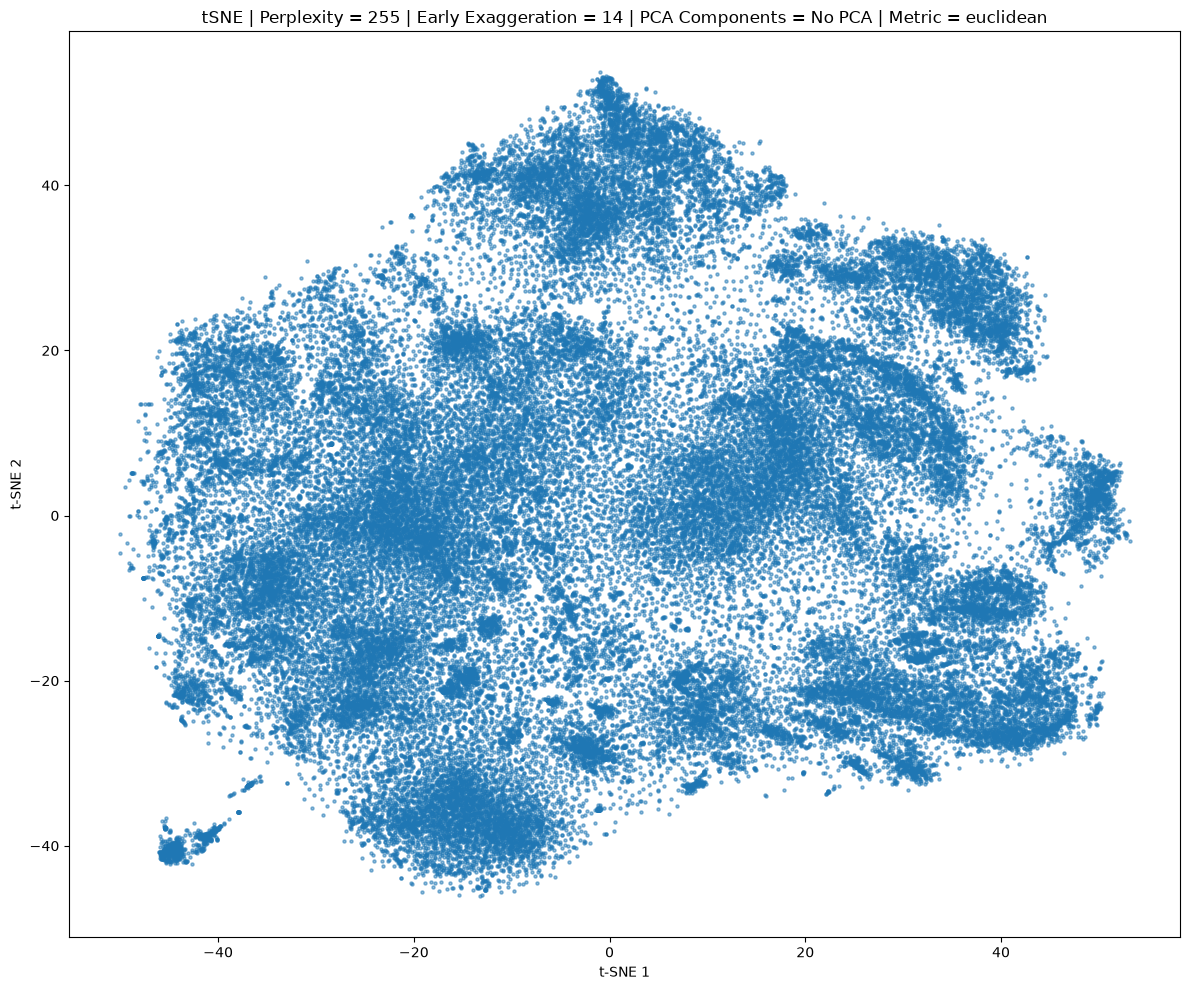

In [43]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_tsne[:, 0], X_tsne[:, 1],s=5,alpha=0.5)
ax.set_title(f"tSNE | Perplexity = {PERPLEXITY} | Early Exaggeration = {EARLY_EXAGGERATION} | PCA Components = No PCA | Metric = {METRIC}")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")

plt.tight_layout()
plt.show()

In [44]:
UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1

In [45]:
umap = UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST, metric=METRIC, random_state=RANDOM_STATE)
X_umap = umap.fit_transform(X_scaled)

/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [46]:
tag = f"umap_nn{UMAP_N_NEIGHBORS}_md{UMAP_MIN_DIST}_{METRIC}_rs{RANDOM_STATE}"
umap_cache = CACHE_DIR / f"TERZ_hw6_ont25_all_years_{tag}.npy"


def run_umap():
    reducer = UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                   metric=METRIC, random_state=RANDOM_STATE)
    return reducer.fit_transform(X_scaled)


X_umap = load_or_compute(umap_cache, run_umap, n_rows=len(X_scaled), force=FORCE_RECOMPUTE)

[cache] loaded TERZ_hw6_ont25_all_years_umap_nn15_md0.1_euclidean_rs42.npy


In [47]:
# Will be used later to acess data in a simpler way

df_umap = pd.DataFrame(X_umap, columns=['umap_1', 'umap_2'])
df_umap.insert(loc=0, column='year', value=df['year'])
df_umap.insert(loc=1, column='station', value=df['station'])
df_umap.insert(loc=2, column='channel', value=df['channel'])
df_umap.insert(loc=3, column='file', value=df['file'])
df_umap.insert(loc=4, column='date', value=df['date'])
df_umap.insert(loc=5, column='month_year', value=df['month_year'])
df_umap.insert(loc=6, column='trigger_time', value=df['trigger_time'])
df_umap.insert(loc=7, column='q_value', value=df['q_value'])

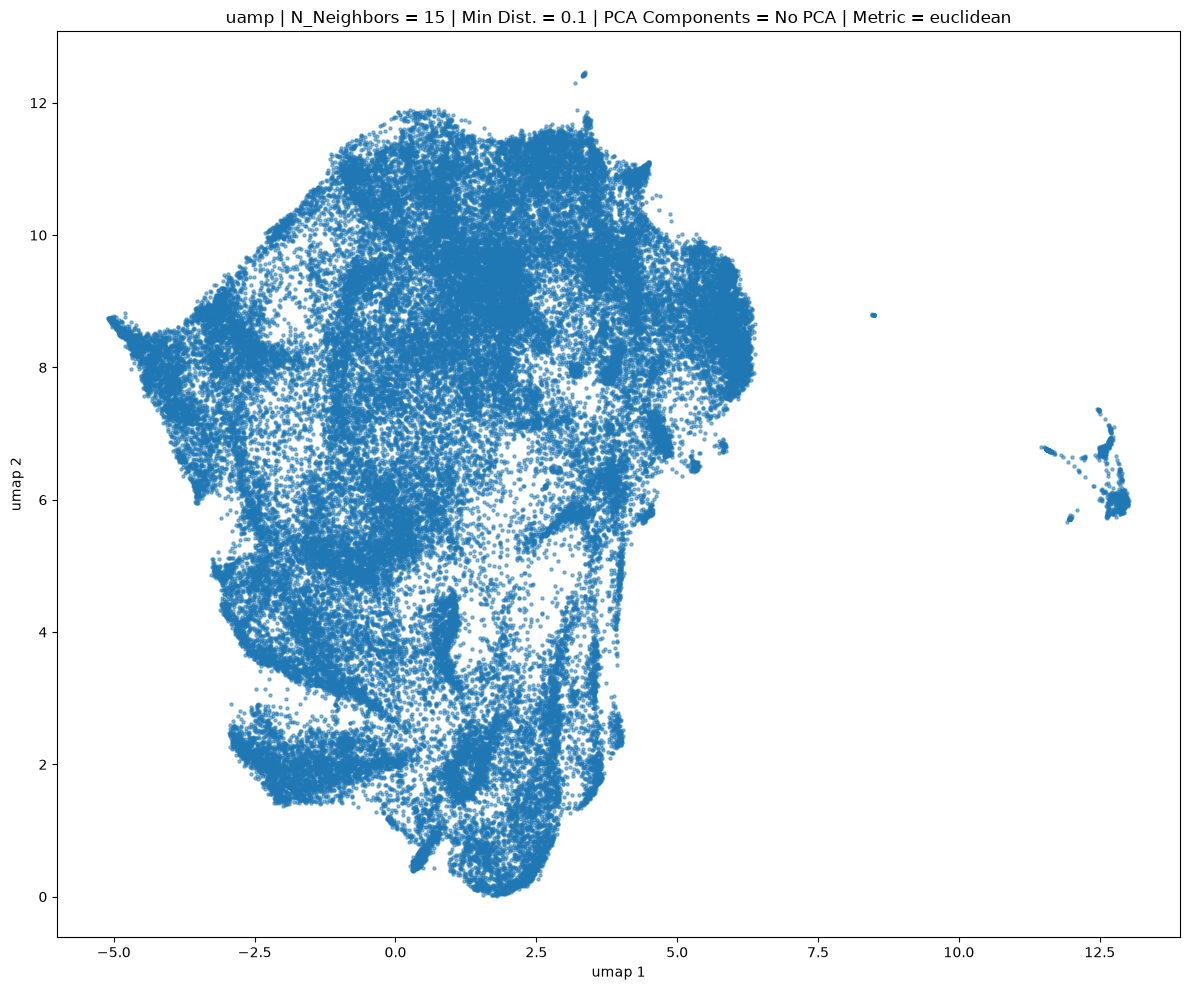

In [48]:
fig, ax = plt.subplots(figsize=(12, 10))
scatter = ax.scatter(X_umap[:, 0], X_umap[:, 1],s=5,alpha=0.5)
ax.set_title(f"uamp | N_Neighbors = {UMAP_N_NEIGHBORS} | Min Dist. = {UMAP_MIN_DIST} | PCA Components = No PCA | Metric = {METRIC}")
ax.set_xlabel("umap 1")
ax.set_ylabel("umap 2")

plt.tight_layout()
plt.show()

## Density Analysis

In [49]:
from scipy.stats import gaussian_kde
from scipy.ndimage import maximum_filter
from sklearn.cluster import HDBSCAN, KMeans
from sklearn.manifold import TSNE

In [50]:
# KDE Gaussian

def density_surface(E, grid):
    """Gaussian KDE of the 2D embedding evaluated on a regular grid."""
    grid = grid
    x, y = E[:, 0], E[:, 1]
    kde = gaussian_kde(np.vstack([x, y]))
    X, Y = np.meshgrid(np.linspace(x.min(), x.max(), grid), np.linspace(y.min(), y.max(), grid))
    Z = kde(np.vstack([X.ravel(), Y.ravel()])).reshape(X.shape)
    return X, Y, Z

In [51]:
X1, Y1, Z1 = density_surface(X_tsne, 100) #tSNE
X2, Y2, Z2 = density_surface(X_umap, 100) #umap

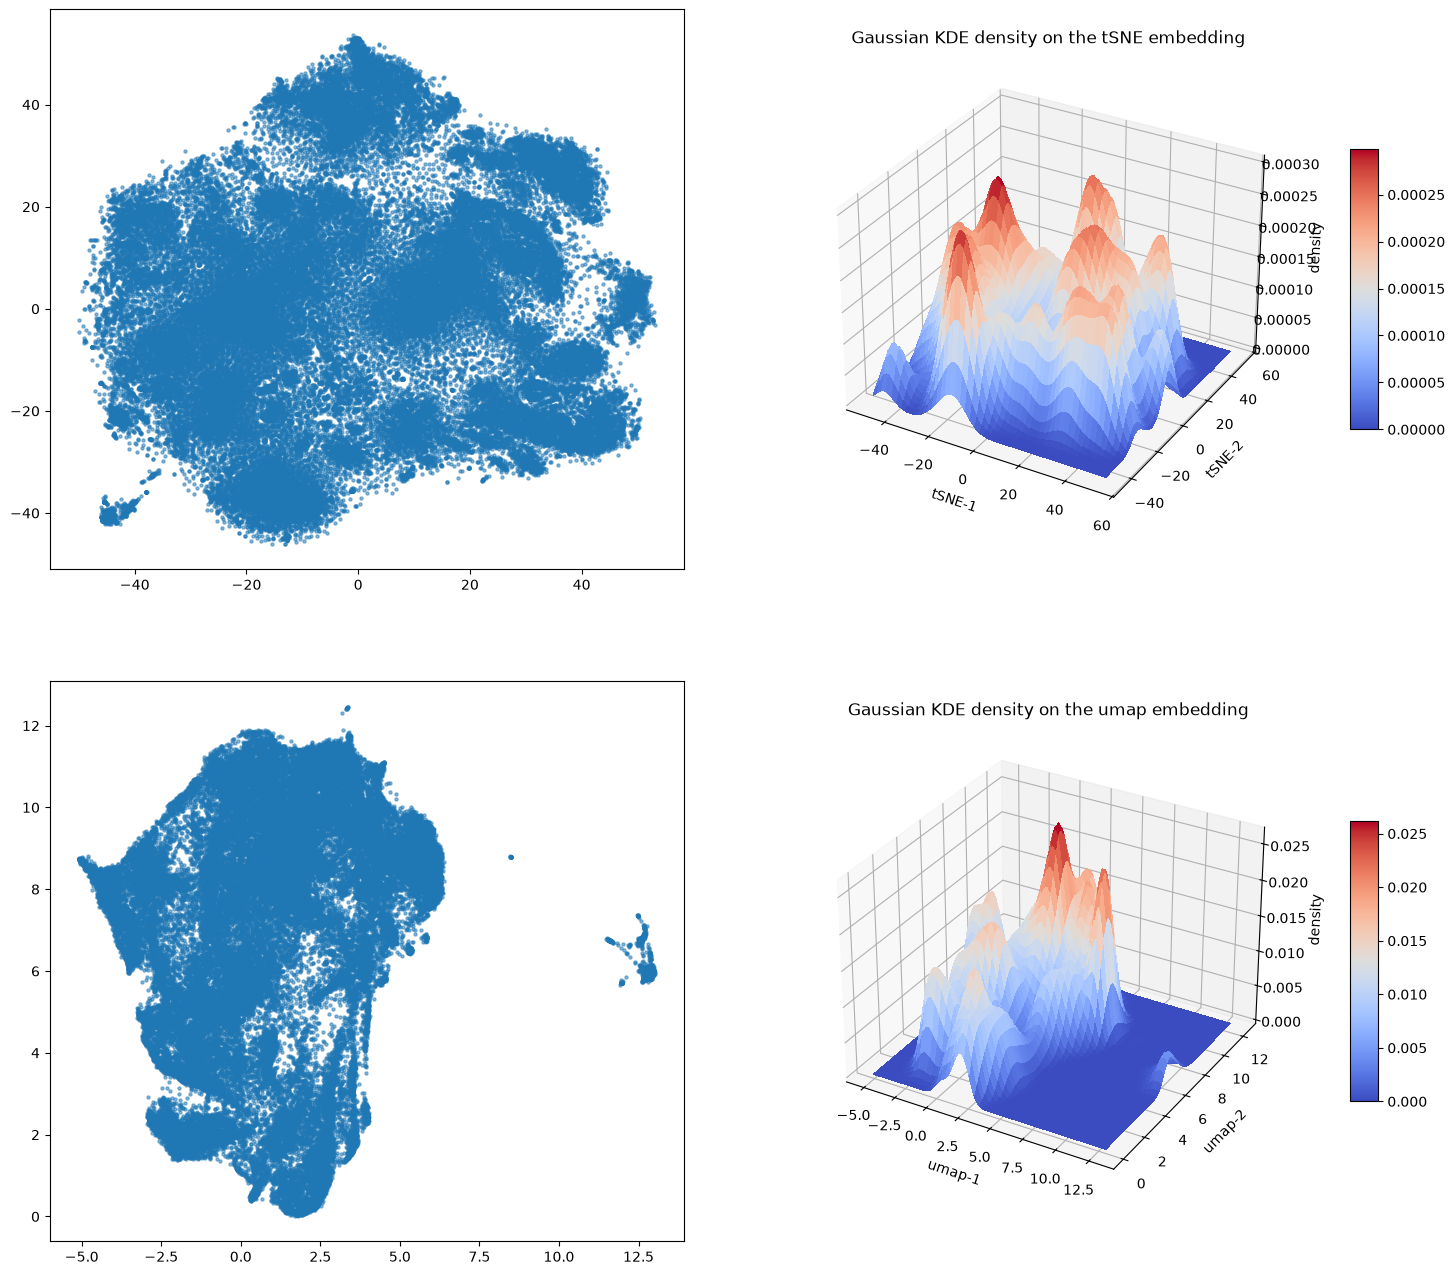

In [52]:
fig = plt.figure(figsize=(18, 16))

ax = fig.add_subplot(2, 2, 1)
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], s=5, alpha=0.5)

ax = fig.add_subplot(2, 2, 2, projection="3d")
surf = ax.plot_surface(X1, Y1, Z1, cmap="coolwarm", linewidth=0, antialiased=False)
ax.set_xlabel("tSNE-1")
ax.set_ylabel("tSNE-2")
ax.set_zlabel("density")
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, pad=0.1)
ax.set_title(f"Gaussian KDE density on the tSNE embedding")

ax = fig.add_subplot(2, 2, 3)
ax.scatter(X_umap[:, 0], X_umap[:, 1], s=5, alpha=0.5)

ax = fig.add_subplot(2, 2, 4, projection="3d")
surf = ax.plot_surface(X2, Y2, Z2, cmap="coolwarm", linewidth=0, antialiased=False)
ax.set_xlabel("umap-1")
ax.set_ylabel("umap-2")
ax.set_zlabel("density")
fig.colorbar(surf, ax=ax, shrink=0.5, aspect=10, pad=0.1)
ax.set_title(f"Gaussian KDE density on the umap embedding")

plt.show()

In [53]:
def kde_peaks(X, Y, Z, size, min_rel):
    """Local maxima of the KDE surface on the grid, tallest first -> ((k, 2) positions, (k,) heights)."""
    is_peak = (Z == maximum_filter(Z, size=size)) & (Z >= min_rel * Z.max())
    rows, cols = np.nonzero(is_peak)
    order = np.argsort(Z[rows, cols])[::-1]
    rows, cols = rows[order], cols[order]
    return np.column_stack([X[rows, cols], Y[rows, cols]]), Z[rows, cols]

## HDBSCAN classification

In [54]:
EMBEDDING_FOR_CLASSES = "tsne"     # "tsne" or "umap"
HDBSCAN_MIN_CLUSTER_SIZE = 750
HDBSCAN_MIN_SAMPLES = 200

In [55]:
if EMBEDDING_FOR_CLASSES == "tsne":
    E, df_emb, emb_name = X_tsne, df_tSNE, "t-SNE"
elif EMBEDDING_FOR_CLASSES == "umap":
    E, df_emb, emb_name = X_umap, df_umap, "UMAP"
else:
    raise ValueError("EMBEDDING_FOR_CLASSES must be 'tsne' or 'umap'")

hdb = HDBSCAN(min_cluster_size=HDBSCAN_MIN_CLUSTER_SIZE, min_samples=HDBSCAN_MIN_SAMPLES)
labels = hdb.fit_predict(E)              # -1 = noise
df_emb["hdbscan_class"] = labels

n_classes = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = int((labels == -1).sum())
print(f"HDBSCAN on {emb_name}: {n_classes} classes, noise = {n_noise} / {len(labels)} ({100 * n_noise / len(labels):.1f}%)")

/home/rauls/Desktop/VirgoBRET/.venv/lib/python3.14/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


HDBSCAN on t-SNE: 9 classes, noise = 18995 / 64382 (29.5%)


In [56]:
# ---- Class per year report ----
counts = pd.crosstab(df_emb["year"], df_emb["hdbscan_class"], margins=True, margins_name="total")
counts = counts.rename(columns={-1: "noise"})
counts.columns.name = "class"

pct = pd.crosstab(df_emb["year"], df_emb["hdbscan_class"], normalize="index") * 100
pct = pct.rename(columns={-1: "noise"})
pct.columns.name = "class"

print("Points per class and year")
print(counts.to_string())
print("\nShare of each year in each class (%)")
print(pct.round(1).to_string())

Points per class and year
class  noise    0     1     2     3     4    5     6      7     8  total
year                                                                    
2022    6347  429  2127  1033  2804  1678  247   788   5033   765  21251
2023    4544  164  1491   838  1853  1411  225   753   3899   404  15582
2024    5108  341  1349   700  2075  1524  307   905   4508   539  17356
2025    2996   28   726   516  1333  1249  194  1017   2044    90  10193
total  18995  962  5693  3087  8065  5862  973  3463  15484  1798  64382

Share of each year in each class (%)
class  noise    0     1    2     3     4    5     6     7    8
year                                                          
2022    29.9  2.0  10.0  4.9  13.2   7.9  1.2   3.7  23.7  3.6
2023    29.2  1.1   9.6  5.4  11.9   9.1  1.4   4.8  25.0  2.6
2024    29.4  2.0   7.8  4.0  12.0   8.8  1.8   5.2  26.0  3.1
2025    29.4  0.3   7.1  5.1  13.1  12.3  1.9  10.0  20.1  0.9


In [57]:
def plot_clusters(ax, E, labels, title, xlabel, ylabel):
    noise = labels == -1
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)

    ax.scatter(E[noise, 0], E[noise, 1], c="lightgray", s=8, alpha=0.5, label="noise")
    ax.scatter(E[~noise, 0], E[~noise, 1], c=labels[~noise], cmap="viridis", s=8, alpha=0.7)
    ax.set_title(f"{title}\n{n_clusters} clusters, {noise.sum()} noise points")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    if noise.any():
        ax.legend(loc="best", markerscale=2)
    return n_clusters, int(noise.sum())

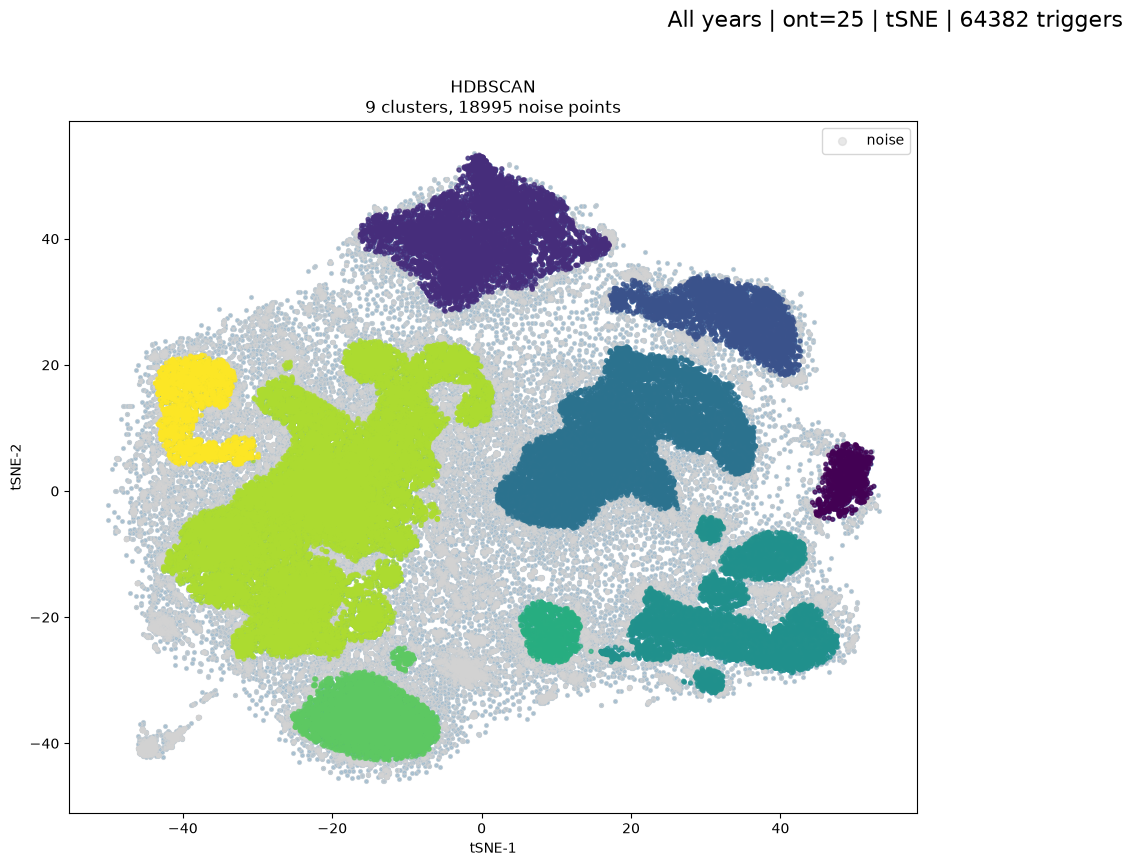

In [58]:
# tSNE embedding with HDBSCAN classes

fig = plt.figure(figsize=(18, 16))

ax = fig.add_subplot(2, 2, 1)
ax.scatter(X_tsne[:, 0], X_tsne[:, 1], s=5, alpha=0.5)
n_hdb, noise_hdb = plot_clusters(ax, E, labels, "HDBSCAN", "tSNE-1", "tSNE-2")
fig.suptitle(f"All years | ont=25 | tSNE | {E.shape[0]} triggers", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.97])

plt.show()

### Thumbnails

In [59]:
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
from matplotlib.lines import Line2D
from PIL import Image

In [60]:
RESULTS_ROOT = Path("TERZ_HHZ_ont25/TERZ_spectrograms_matrix_results_cut_hw6_ont25")   # EDIT: folder that contains the qtransform PDFs
PDF_INDEX_ORDER = "df"
N_THUMBS_PER_CLASS = 30
MIN_DIST_FRAC = 0.04       # minimum distance between two thumbnails, as a fraction of the plot span
THUMB_PX = 120             # width in pixels of each rendered thumbnail
THUMB_ZOOM = 0.35          # size of the thumbnails on the figure
THUMB_SEED = 0

In [61]:
DAY_KEY = ["station", "channel", "date"]
if PDF_INDEX_ORDER == "df":
    df_emb["pdf_index"] = df_emb.groupby(DAY_KEY, sort=False).cumcount()
elif PDF_INDEX_ORDER == "time":
    _t = pd.to_datetime(df_emb["trigger_time"], utc=True)
    df_emb["pdf_index"] = df_emb.assign(_t=_t).groupby(DAY_KEY, sort=False)["_t"].rank(method="first").astype(int) - 1
else:
    raise ValueError("PDF_INDEX_ORDER must be 'df' or 'time'")


def qtransform_pdf_path(row):
    """Path of the qtransform PDF of one row of df_emb.
    Layout: <RESULTS_ROOT>/<year>/<station>/<channel>/<month_year>/qtransform_<YYYYMMDD>_<pdf_index, 6 digits>.pdf"""
    day = pd.to_datetime(row["date"]).strftime("%Y%m%d")
    return (RESULTS_ROOT / str(row["year"]) / str(row["station"]) / str(row["channel"])
            / str(row["month_year"]) / f"qtransform_{day}_{int(row['pdf_index']):06d}.pdf")


# quick check of the path rule
#for _, row in df_emb.sample(5, random_state=0).iterrows():
#    p = qtransform_pdf_path(row)
#    print(("OK      " if p.exists() else "MISSING ") + str(p))
#_sample = df_emb.sample(min(200, len(df_emb)), random_state=1)
#_found = sum(qtransform_pdf_path(r).exists() for _, r in _sample.iterrows())
#print(f"PDF found for {_found} of {len(_sample)} random rows")

In [62]:
def render_pdf_first_page(path, width_px=THUMB_PX):
    """Page 1 of a PDF as an RGB array. Uses PyMuPDF, pypdfium2 or pdf2image, whichever is installed."""
    try:
        import fitz                                  # PyMuPDF
    except ImportError:
        fitz = None
    if fitz is not None:
        with fitz.open(path) as doc:
            page = doc[0]
            zoom = width_px / page.rect.width
            pix = page.get_pixmap(matrix=fitz.Matrix(zoom, zoom), colorspace=fitz.csRGB, alpha=False)
            return np.asarray(Image.frombytes("RGB", (pix.width, pix.height), pix.samples))
    try:
        import pypdfium2 as pdfium
    except ImportError:
        pdfium = None
    if pdfium is not None:
        pdf = pdfium.PdfDocument(str(path))
        try:
            page = pdf[0]
            return np.asarray(page.render(scale=width_px / page.get_width()).to_pil().convert("RGB"))
        finally:
            pdf.close()
    from pdf2image import convert_from_path
    img = convert_from_path(str(path), dpi=50, first_page=1, last_page=1)[0].convert("RGB")
    return np.asarray(img.resize((width_px, int(img.height * width_px / img.width))))


def pick_thumbnails(E, labels, df_emb, per_class, min_dist_frac, seed):
    """Random points of each class (noise included), spread out so the thumbnails do not pile up.
    Points whose PDF cannot be opened are skipped. Returns a list of (row index, image)."""
    rng = np.random.default_rng(seed)
    En = E / np.ptp(E, axis=0)
    chosen, picks, n_fail = [], [], 0
    for c in np.unique(labels):
        n_taken, fails = 0, 0
        for i in rng.permutation(np.flatnonzero(labels == c)):
            if n_taken >= per_class or fails >= 5 * per_class:
                break
            if chosen and np.hypot(*(En[chosen].T - En[i][:, None])).min() < min_dist_frac:
                continue
            try:
                img = render_pdf_first_page(qtransform_pdf_path(df_emb.iloc[i]))
            except Exception:
                fails += 1
                continue
            chosen.append(i)
            picks.append((i, img))
            n_taken += 1
        n_fail += fails
    if not picks:
        raise RuntimeError("No qtransform PDF could be opened: check RESULTS_ROOT and qtransform_pdf_path().")
    print(f"{len(picks)} thumbnails placed, {n_fail} PDFs skipped (missing or unreadable)")
    return picks


167 thumbnails placed, 0 PDFs skipped (missing or unreadable)


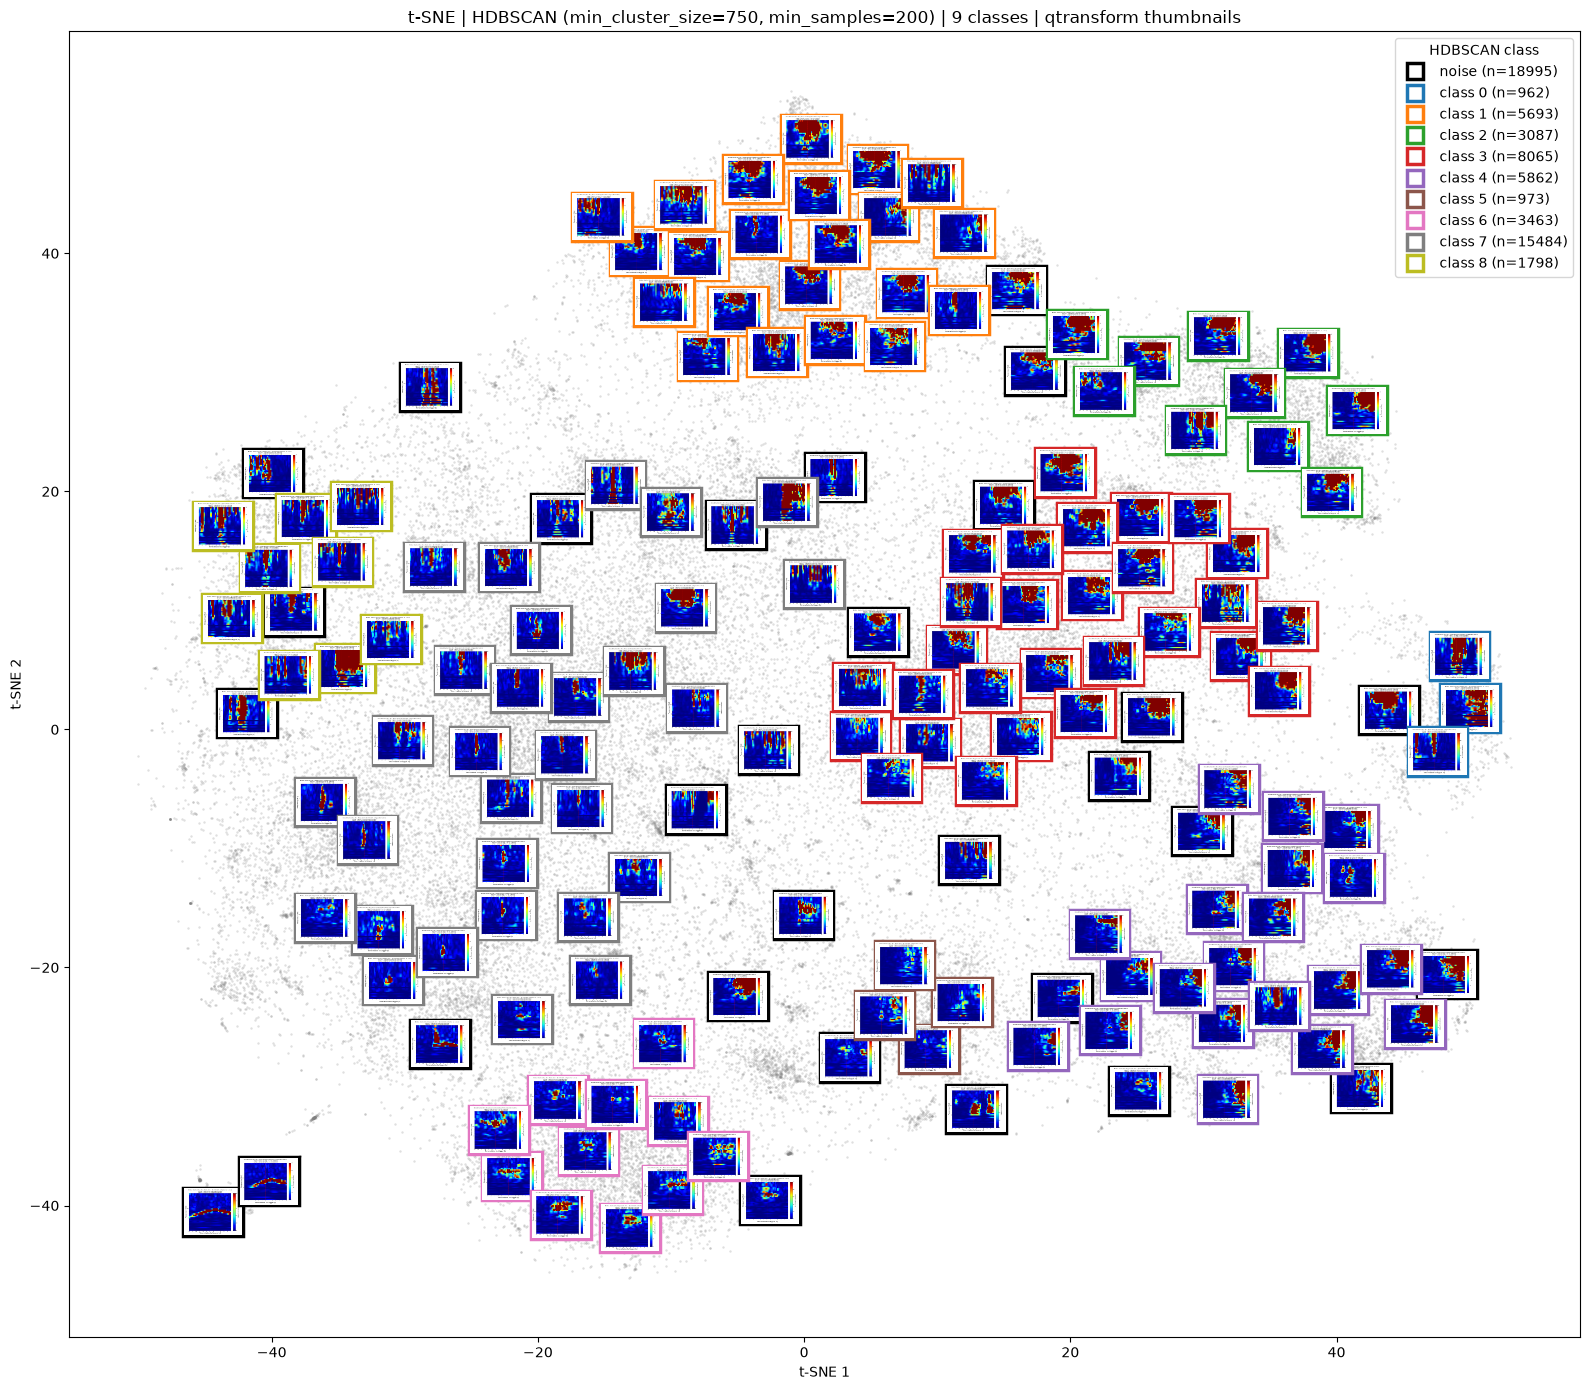

In [63]:
picks = pick_thumbnails(E, labels, df_emb, N_THUMBS_PER_CLASS, MIN_DIST_FRAC, THUMB_SEED)

class_ids = [c for c in np.unique(labels) if c != -1]
cmap = plt.get_cmap("tab10" if len(class_ids) <= 10 else "tab20")
colors = {c: cmap(k % cmap.N) for k, c in enumerate(class_ids)}
colors[-1] = "black"

fig, ax = plt.subplots(figsize=(16, 14))
ax.scatter(E[:, 0], E[:, 1], s=3, c="gray", alpha=0.25, linewidths=0, rasterized=True)
for i, img in picks:
    ab = AnnotationBbox(OffsetImage(img, zoom=THUMB_ZOOM), (E[i, 0], E[i, 1]), frameon=True, pad=0.05,
                        bboxprops=dict(edgecolor=colors[labels[i]], facecolor="white", linewidth=2.5))
    ax.add_artist(ab)

handles = []
for c in [-1] + class_ids:
    name = "noise" if c == -1 else f"class {c}"
    handles.append(Line2D([0], [0], marker="s", linestyle="", markerfacecolor="white", markeredgecolor=colors[c],
                          markeredgewidth=2.5, markersize=11, label=f"{name} (n={int((labels == c).sum())})"))
ax.legend(handles=handles, loc="best", title="HDBSCAN class")
ax.set_title(f"{emb_name} | HDBSCAN (min_cluster_size={HDBSCAN_MIN_CLUSTER_SIZE}, "
             f"min_samples={HDBSCAN_MIN_SAMPLES}) | {n_classes} classes | qtransform thumbnails")
ax.set_xlabel(f"{emb_name} 1")
ax.set_ylabel(f"{emb_name} 2")
plt.tight_layout()
fig.savefig(f"thumbs_TERZ_all_hdbscan_{EMBEDDING_FOR_CLASSES}.png", dpi=150)
plt.show()

## Balanced subplot

Classes kept: [1, 2, 3, 4, 6, 7, 8] | dropped (fewer than 1000 points): {0: 962, 5: 973}
Subsample: 7000 points -> {1: 1000, 2: 1000, 3: 1000, 4: 1000, 6: 1000, 7: 1000, 8: 1000}
[cache] no valid cache for TERZ_hw6_ont25_sub7000_23eb48f3_tsne_perp100_ee14_euclidean_rs42.npy -> computing
[cache] saved TERZ_hw6_ont25_sub7000_23eb48f3_tsne_perp100_ee14_euclidean_rs42.npy
[cache] loaded TERZ_hw6_ont25_sub7000_23eb48f3_umap_nn15_md0.1_euclidean_rs42.npy


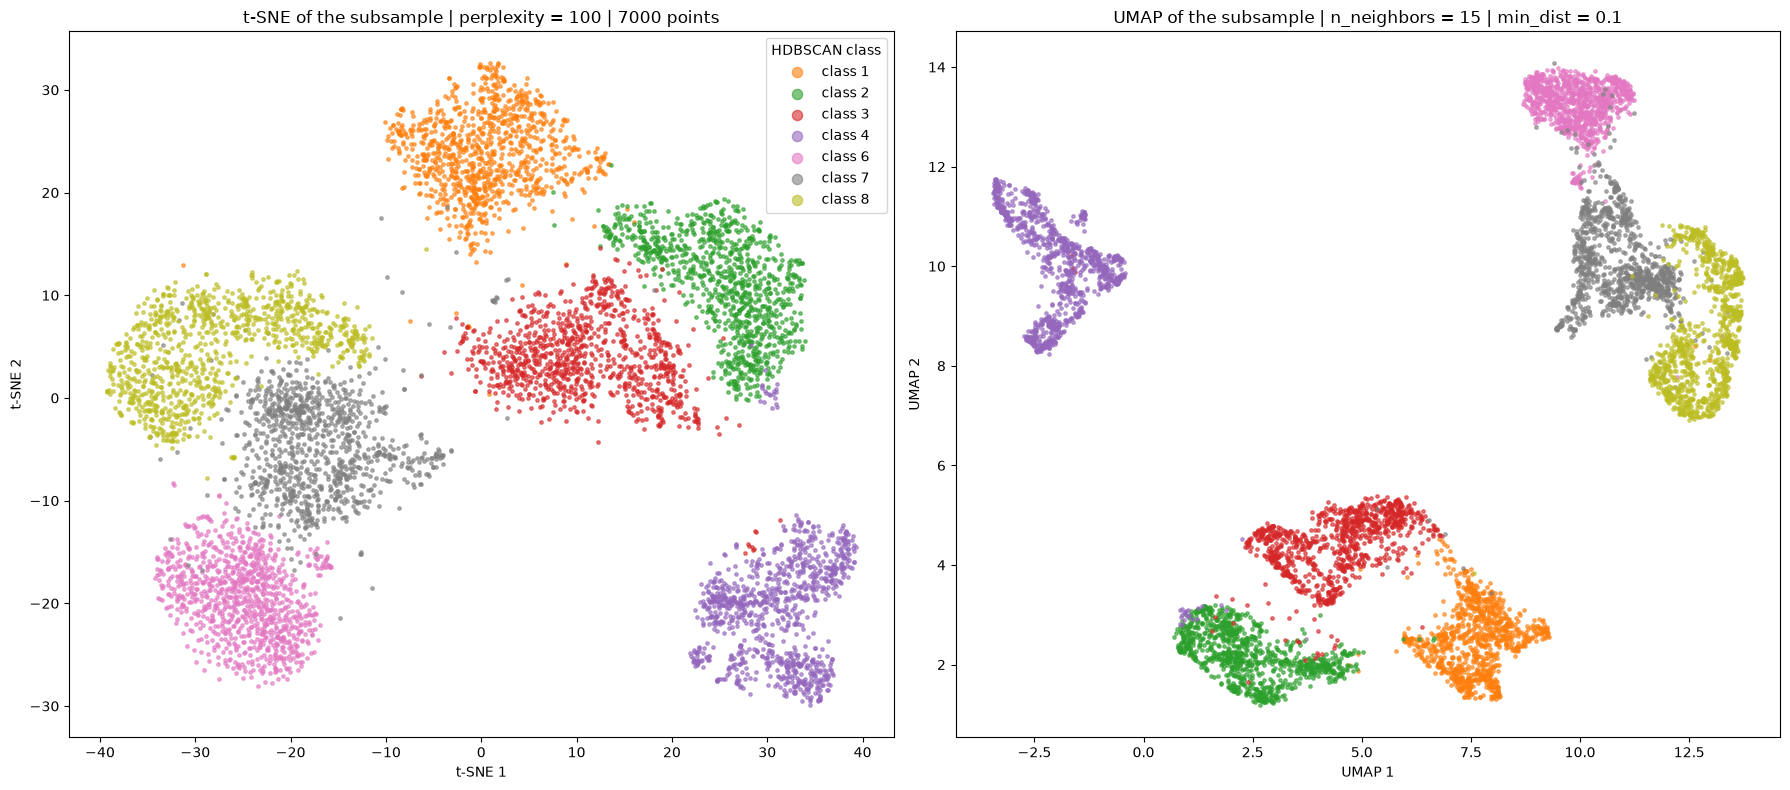

In [65]:
import hashlib

# Settings
PER_CLASS = 1000          # points drawn from each class
MIN_CLASS_SIZE = 1000     # classes with fewer points are dropped (lower it to keep small classes: they contribute all their points)
SAMPLE_SEED = 42
PERPLEXITY_SUB = 100      # None -> sqrt(number of sampled points), the same rule used for the full set

# 1) Draw PER_CLASS points from every class with at least MIN_CLASS_SIZE points (noise, -1, is left out)
rng = np.random.default_rng(SAMPLE_SEED)
class_sizes = pd.Series(labels[labels != -1]).value_counts().sort_index()
kept = class_sizes[class_sizes >= MIN_CLASS_SIZE].index.tolist()
dropped = class_sizes[class_sizes < MIN_CLASS_SIZE].to_dict()
if not kept:
    raise ValueError(f"No class has at least {MIN_CLASS_SIZE} points (class sizes: {class_sizes.to_dict()})")

idx = np.sort(np.concatenate([rng.choice(np.flatnonzero(labels == c), size=min(PER_CLASS, int(class_sizes.loc[c])), replace=False) for c in kept]))



sub_labels = labels[idx]
n_sub = len(idx)
print(f"Classes kept: {kept} | dropped (fewer than {MIN_CLASS_SIZE} points): {dropped}")
print(f"Subsample: {n_sub} points -> {pd.Series(sub_labels).value_counts().sort_index().to_dict()}")

# 2) New t-SNE and UMAP on the features of the sampled points (same preprocessing as the full set), with the cache
X_sub = X_scaled[idx]
perp_sub = PERPLEXITY_SUB or int(round(np.sqrt(n_sub)))
sub_id = hashlib.md5(idx.tobytes()).hexdigest()[:8]      # changes whenever the sampled points change


def run_tsne_sub():
    return TSNE(n_components=2, perplexity=perp_sub, early_exaggeration=EARLY_EXAGGERATION, init="pca",
                learning_rate="auto", random_state=RANDOM_STATE, metric=METRIC).fit_transform(X_sub)

def run_umap_sub():
    return UMAP(n_components=2, n_neighbors=UMAP_N_NEIGHBORS, min_dist=UMAP_MIN_DIST,
                metric=METRIC, random_state=RANDOM_STATE).fit_transform(X_sub)


tsne_sub_cache = CACHE_DIR / (f"TERZ_hw6_ont25_sub{n_sub}_{sub_id}_tsne_perp{perp_sub}_ee{EARLY_EXAGGERATION}_{METRIC}_rs{RANDOM_STATE}.npy")
umap_sub_cache = CACHE_DIR / (f"TERZ_hw6_ont25_sub{n_sub}_{sub_id}_umap_nn{UMAP_N_NEIGHBORS}_md{UMAP_MIN_DIST}_{METRIC}_rs{RANDOM_STATE}.npy")
X_tsne_sub = load_or_compute(tsne_sub_cache, run_tsne_sub, n_rows=n_sub, force=FORCE_RECOMPUTE)
X_umap_sub = load_or_compute(umap_sub_cache, run_umap_sub, n_rows=n_sub, force=FORCE_RECOMPUTE)

# 3) Table of the sampled points: metadata + class + the new coordinates (orig_index = row of the full dataset)
df_sub = df_emb.iloc[idx].copy()
df_sub.insert(0, "orig_index", idx)
df_sub["sub_tSNE_1"], df_sub["sub_tSNE_2"] = X_tsne_sub[:, 0], X_tsne_sub[:, 1]
df_sub["sub_umap_1"], df_sub["sub_umap_2"] = X_umap_sub[:, 0], X_umap_sub[:, 1]
df_sub = df_sub.reset_index(drop=True)

# 4) Quick look, coloured by HDBSCAN class (same colours as the thumbnail figure)
all_ids = [c for c in np.unique(labels) if c != -1]
cmap = plt.get_cmap("tab10" if len(all_ids) <= 10 else "tab20")
class_color = {c: cmap(k % cmap.N) for k, c in enumerate(all_ids)}

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, E_sub, name in zip(axes, (X_tsne_sub, X_umap_sub), ("t-SNE", "UMAP")):
    for c in kept:
        m = sub_labels == c
        ax.scatter(E_sub[m, 0], E_sub[m, 1], s=6, alpha=0.6, color=class_color[c], label=f"class {c}")
    ax.set_xlabel(f"{name} 1")
    ax.set_ylabel(f"{name} 2")
axes[0].set_title(f"t-SNE of the subsample | perplexity = {perp_sub} | {n_sub} points")
axes[1].set_title(f"UMAP of the subsample | n_neighbors = {UMAP_N_NEIGHBORS} | min_dist = {UMAP_MIN_DIST}")
axes[0].legend(markerscale=3, title="HDBSCAN class")
plt.tight_layout()
plt.show()

188 thumbnails placed, 0 PDFs skipped (missing or unreadable)


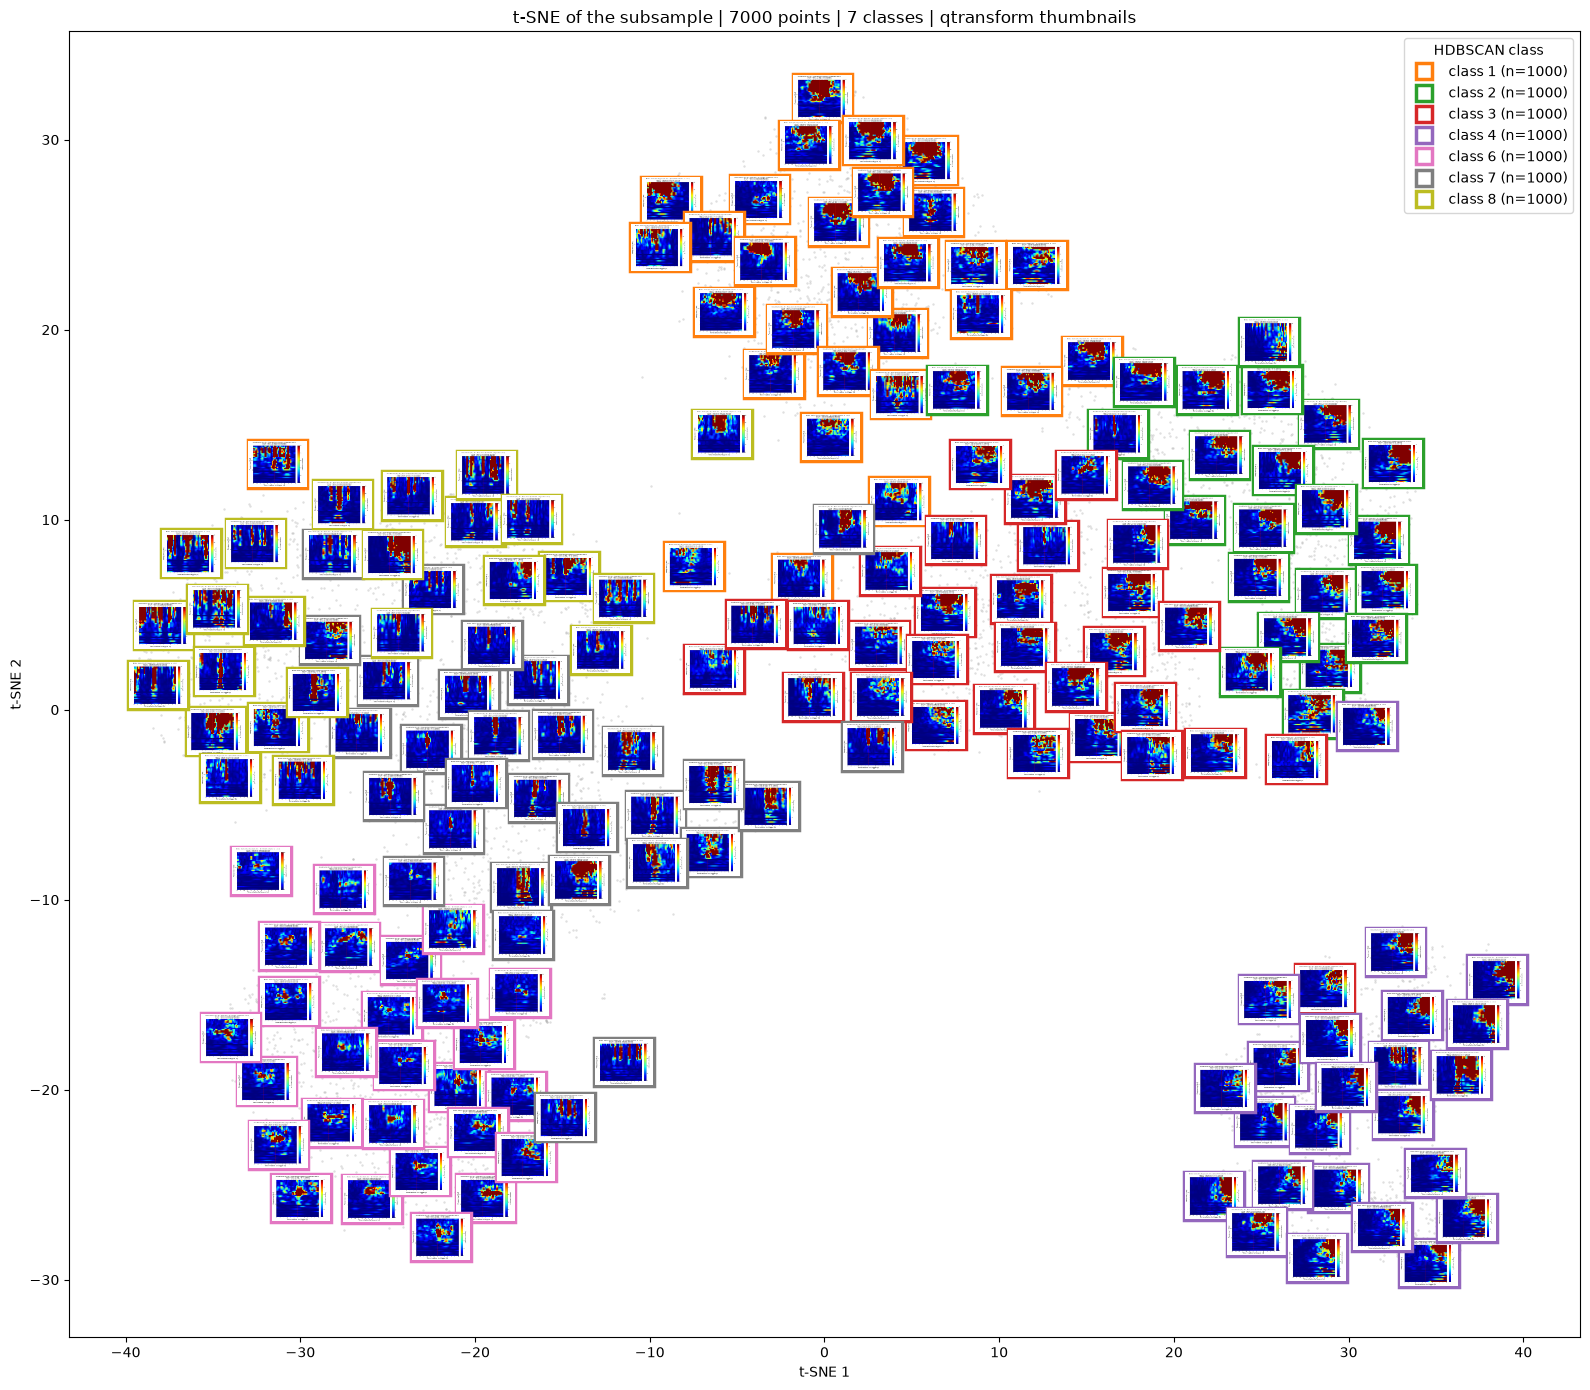

92 thumbnails placed, 0 PDFs skipped (missing or unreadable)


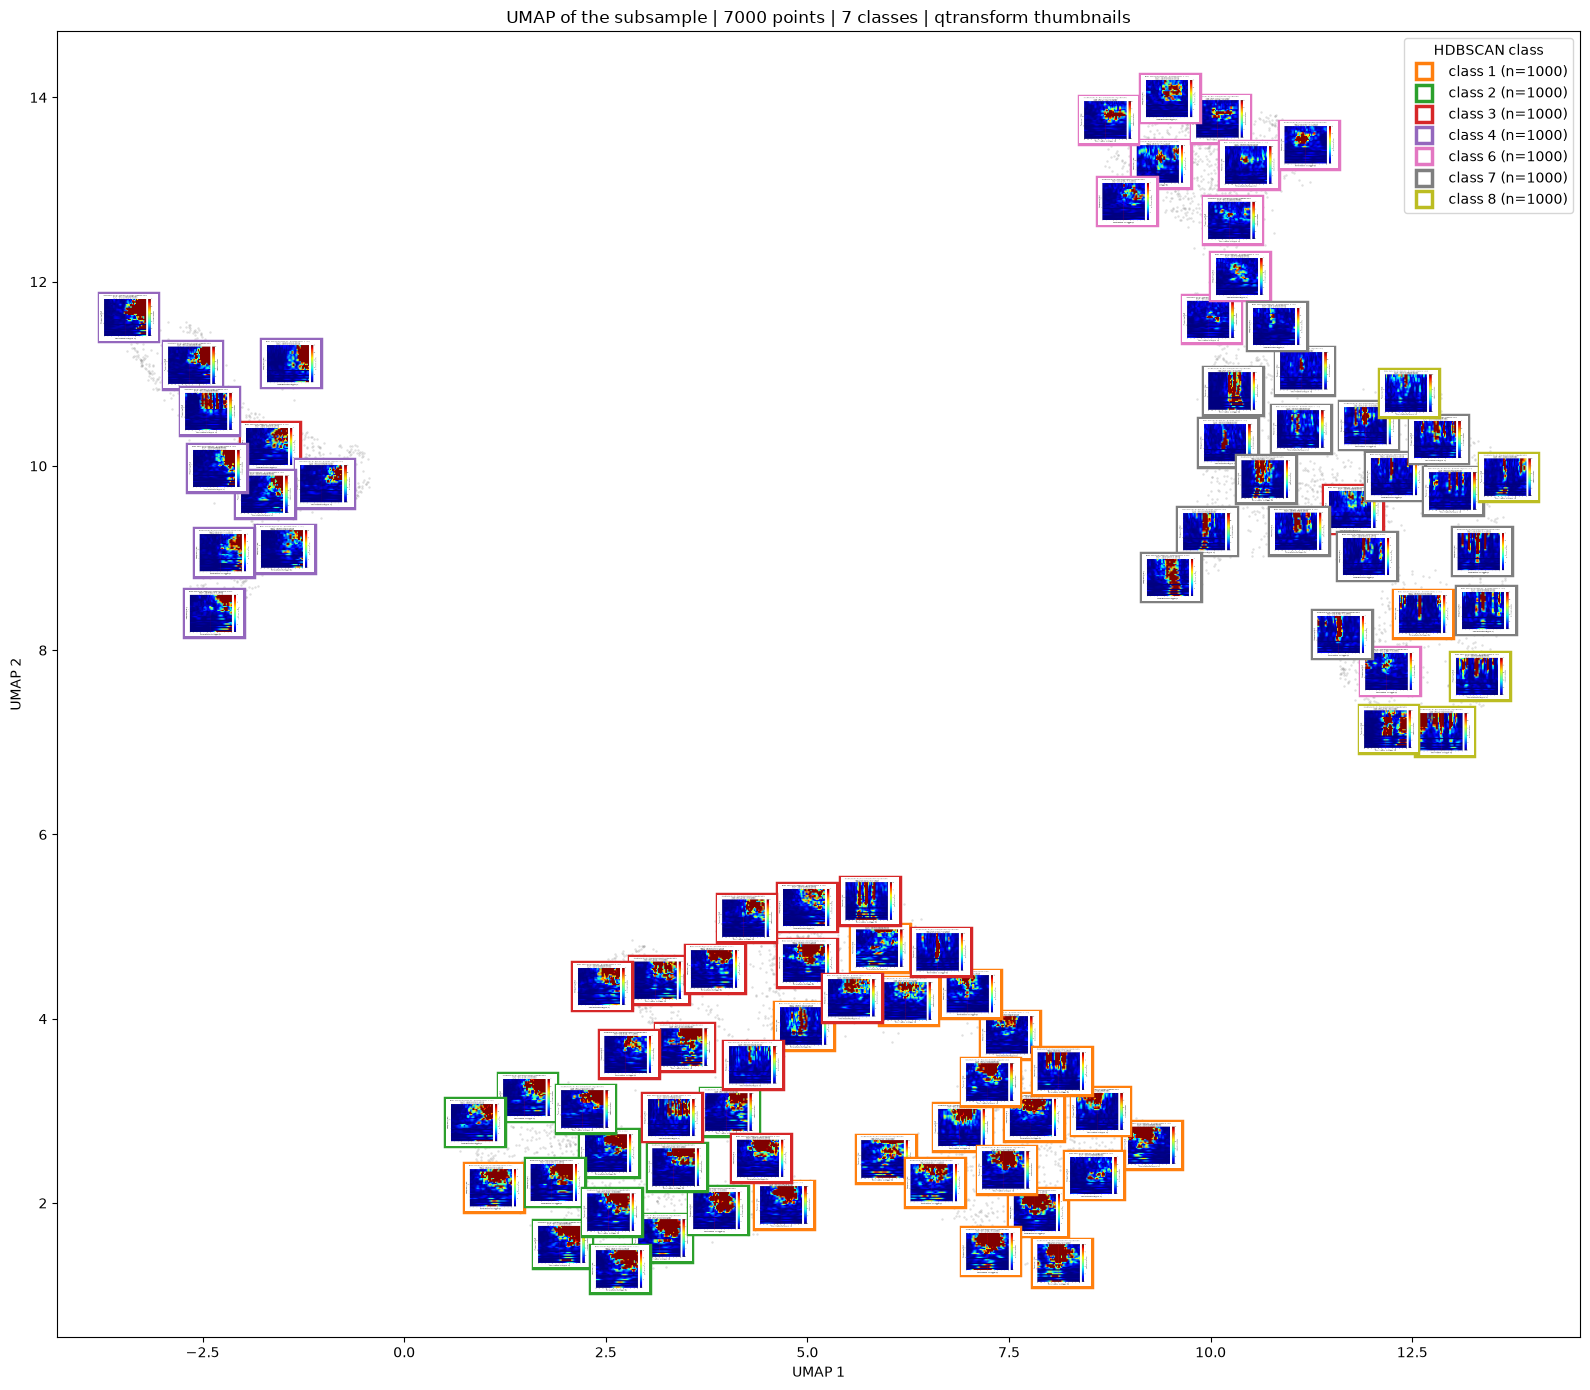

In [66]:
df_sub["pdf_index"] = df_emb["pdf_index"].to_numpy()[df_sub["orig_index"].to_numpy()]
 
 
def plot_sub_thumbs(E, name, fname):
    picks = pick_thumbnails(E, sub_labels, df_sub, N_THUMBS_PER_CLASS, MIN_DIST_FRAC, THUMB_SEED)
 
    fig, ax = plt.subplots(figsize=(16, 14))
    ax.scatter(E[:, 0], E[:, 1], s=3, c="gray", alpha=0.25, linewidths=0, rasterized=True)
    for i, img in picks:
        ab = AnnotationBbox(OffsetImage(img, zoom=THUMB_ZOOM), (E[i, 0], E[i, 1]), frameon=True, pad=0.05, bboxprops=dict(edgecolor=class_color[sub_labels[i]], facecolor="white", linewidth=2.5))
        ax.add_artist(ab)
 
    handles = [Line2D([0], [0], marker="s", linestyle="", markerfacecolor="white", markeredgecolor=class_color[c], markeredgewidth=2.5, markersize=11, label=f"class {c} (n={int((sub_labels == c).sum())})")
               for c in kept]
    ax.legend(handles=handles, loc="best", title="HDBSCAN class")
    ax.set_title(f"{name} of the subsample | {n_sub} points | {len(kept)} classes | qtransform thumbnails")
    ax.set_xlabel(f"{name} 1")
    ax.set_ylabel(f"{name} 2")
    plt.tight_layout()
    fig.savefig(fname, dpi=150)
    plt.show()
 
 
plot_sub_thumbs(X_tsne_sub, "t-SNE", "thumbs_TERZ_sub_tsne.png")
plot_sub_thumbs(X_umap_sub, "UMAP", "thumbs_TERZ_sub_umap.png")